Chronos zero-shot on wind power generation data (Kaggle) - multihorizon comparision

No training pipeline needed - Chronos is a pretrained model used purely zero-shot : it never sees this dataset during training, only as forecast context at inference time

1. Install dependencies

In [ ]:
!pip install -q chronos-forecasting pandas numpy torch

In [ ]:
import glob
import os
import time
import numpy as np
import pandas as pd
import torch
from chronos import ChronosPipeline

2. Configuration

In [ ]:
DATA_DIR = "/content/Dataset"
HORIZONS = [24, 48, 96, 192, 336]
MAX_PREDICTION_LENGTH_RECOMMENDED = 64 # Max prediction length recommended by Chronos model
CONTEXT_LEN = 512                          # matches PatchTST's INPUT_LEN for a fair compute/latency comparison
TEST_FRAC = 0.20
NUM_SAMPLES = 20                           # Chronos forecasts probabilistically; we take the median as the point forecast
RANDOM_SEED = 42
RESULTS_CSV = "results_chronos_wind.csv"

MODEL_NAME = "amazon/chronos-t5-small"

DATETIME_HINTS = ["date/time", "date_time", "datetime", "timestamp", "date", "time"]
TARGET_HINTS = [
    "lv activepower", "active power", "activepower", "power (kw)", "power(kw)",
    "power output", "generated power", "wind power", "power",
]
TARGET_EXCLUDE_HINTS = ["theoretical", "curve"]
MANUAL_OVERRIDES = {}

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

3. Load pretrained Chronos pipeline (zero-shot, no training)

In [ ]:
pipeline = ChronosPipeline.from_pretrained(
    MODEL_NAME,
    device_map=DEVICE,
    torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
)
n_params = sum(p.numel() for p in pipeline.model.parameters())
print(f"Loaded {MODEL_NAME} on {DEVICE}, {n_params:,} parameters.")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loaded amazon/chronos-t5-small on cuda, 46,154,240 parameters.


4. Load + auto-detect columns

In [ ]:
def find_column(columns, hints, exclude_hints=None):
    cols_lower = {c: c.lower() for c in columns}
    exclude_hints = exclude_hints or []
    for hint in hints:
        for c, cl in cols_lower.items():
            if hint in cl and not any(ex in cl for ex in exclude_hints):
                return c
    return None


def load_one_csv(path):
    fname = os.path.basename(path)
    df = pd.read_csv(path)

    override = MANUAL_OVERRIDES.get(fname, {})
    dt_col = override.get("datetime") or find_column(df.columns, DATETIME_HINTS)
    target_col = override.get("target") or find_column(
        df.columns, TARGET_HINTS, exclude_hints=TARGET_EXCLUDE_HINTS
    )

    if dt_col is None or target_col is None:
        print(f"  [SKIP] {fname}: could not auto-detect columns "
              f"(datetime={dt_col}, target={target_col}).")
        return None

    print(f"  [OK]   {fname}: datetime_col='{dt_col}', target_col='{target_col}'")

    out = pd.DataFrame()
    out["ds"] = pd.to_datetime(df[dt_col], errors="coerce", dayfirst=True)
    out["y"] = pd.to_numeric(df[target_col], errors="coerce")
    out["unique_id"] = os.path.splitext(fname)[0]
    out = out.dropna(subset=["ds", "y"]).sort_values("ds")
    out = out.drop_duplicates(subset=["ds"])
    return out.reset_index(drop=True)


csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
if not csv_paths:
    raise FileNotFoundError(f"No .csv files found in {DATA_DIR}.")

print(f"Found {len(csv_paths)} CSV file(s) in {DATA_DIR}:")
frames = [load_one_csv(p) for p in csv_paths]
frames = [f for f in frames if f is not None and len(f) > (CONTEXT_LEN + max(HORIZONS) + 10)]

if not frames:
    raise ValueError(
        "No usable series after loading. Check MANUAL_OVERRIDES or series length "
        "relative to CONTEXT_LEN + max(HORIZONS)."
    )

df = pd.concat(frames, ignore_index=True)
print(f"\nLoaded {df.unique_id.nunique()} series, {len(df)} total rows.")

Found 4 CSV file(s) in /content/Dataset:
  [OK]   Location1.csv: datetime_col='Time', target_col='Power'
  [OK]   Location2.csv: datetime_col='Time', target_col='Power'
  [OK]   Location3.csv: datetime_col='Time', target_col='Power'
  [OK]   Location4.csv: datetime_col='Time', target_col='Power'

Loaded 4 series, 69024 total rows.


5. Build per-series test contexts

In [ ]:
def make_test_contexts(df, horizon):
    contexts = {}
    for uid, g in df.groupby("unique_id"):
        g = g.sort_values("ds").reset_index(drop=True)
        n = len(g)
        n_test = max(int(n * TEST_FRAC), horizon + 10)
        n_train_full = n - n_test
        if n_train_full < CONTEXT_LEN:
            continue  # not enough history before the test region
        ctx_full = g.iloc[max(n_train_full - CONTEXT_LEN, 0):].reset_index(drop=True)
        contexts[uid] = ctx_full
    return contexts

6. Zero-shot rolling evaluation for one horizon, across all series

In [ ]:
def run_one(df, horizon):
    contexts = make_test_contexts(df, horizon)
    if not contexts:
        print(f"  [SKIP] horizon={horizon}: no series long enough.")
        return None

    preds_all, actuals_all, latencies = [], [], []
    step = horizon  # non-overlapping windows

    for uid, ctx_full in contexts.items():
        n_windows = max((len(ctx_full) - CONTEXT_LEN - horizon) // step + 1, 0)

        for w in range(n_windows):
            start = CONTEXT_LEN + w * step
            hist = ctx_full.iloc[start - CONTEXT_LEN:start]["y"].values
            true_future = ctx_full.iloc[start:start + horizon]["y"].values
            if len(true_future) < horizon or len(hist) < CONTEXT_LEN:
                break

            current_context = torch.tensor(hist, dtype=torch.float32)
            predicted_values = []
            remaining_prediction_length = horizon

            # Perform chunked prediction for horizons > MAX_PREDICTION_LENGTH_RECOMMENDED
            while remaining_prediction_length > 0:
                chunk_prediction_length = min(remaining_prediction_length, MAX_PREDICTION_LENGTH_RECOMMENDED)

                t0 = time.time()
                chunk_forecast_output = pipeline.predict(
                    current_context,
                    prediction_length=chunk_prediction_length,
                    num_samples=NUM_SAMPLES,
                )
                latencies.append((time.time() - t0) * 1000)

                # forecast shape: [1, num_samples, horizon] -> take median across samples
                median_chunk_pred = np.median(chunk_forecast_output[0].numpy(), axis=0)
                predicted_values.extend(median_chunk_pred)

                remaining_prediction_length -= chunk_prediction_length

                # Update context for the next chunk: append the newly predicted values
                # and keep only the last CONTEXT_LEN elements for the next prediction.
                combined_sequence = np.concatenate((current_context.numpy(), median_chunk_pred))
                current_context = torch.tensor(
                    combined_sequence[-CONTEXT_LEN:],
                    dtype=torch.float32
                )

            # After the loop, predicted_values contains the full horizon prediction
            median_pred = np.array(predicted_values)

            preds_all.append(median_pred)
            actuals_all.append(true_future)

    if not preds_all:
        print(f"  [SKIP] horizon={horizon}: no evaluable windows.")
        return None

    preds_all = np.concatenate(preds_all)
    actuals_all = np.concatenate(actuals_all)

    mse = float(np.mean((preds_all - actuals_all) ** 2))
    mae = float(np.mean(np.abs(preds_all - actuals_all)))
    avg_latency_ms = float(np.mean(latencies))

    return {
        "horizon": horizon,
        "mse": mse,
        "mae": mae,
        "inference_latency_ms": round(avg_latency_ms, 2),
        "n_params": n_params,
        "n_series_used": len(contexts),
        "model_name": MODEL_NAME,
    }

Output: results_chronos_wind.csv with columns horizon, mse, mae,inference_latency_ms, n_params, n_series_used, model_name

7. Sweep all horizons (no train_frac loop — zero-shot means no training)

In [ ]:
results = []
for h in HORIZONS:
    print(f"\n=== Horizon={h} (zero-shot) ===")
    res = run_one(df, h)
    if res is not None:
        print(res)
        results.append(res)

results_df = pd.DataFrame(results)
results_df.to_csv(RESULTS_CSV, index=False)
print(f"\nSaved results to {RESULTS_CSV}")
print(results_df)


=== Horizon=24 (zero-shot) ===
{'horizon': 24, 'mse': 0.05110447900026589, 'mae': 0.1487509742282911, 'inference_latency_ms': 329.95, 'n_params': 46154240, 'n_series_used': 4, 'model_name': 'amazon/chronos-t5-small'}

=== Horizon=48 (zero-shot) ===
{'horizon': 48, 'mse': 0.05924947055277372, 'mae': 0.168130637629957, 'inference_latency_ms': 608.3, 'n_params': 46154240, 'n_series_used': 4, 'model_name': 'amazon/chronos-t5-small'}

=== Horizon=96 (zero-shot) ===
{'horizon': 96, 'mse': 0.07546719457638694, 'mae': 0.19007661669863843, 'inference_latency_ms': 605.1, 'n_params': 46154240, 'n_series_used': 4, 'model_name': 'amazon/chronos-t5-small'}

=== Horizon=192 (zero-shot) ===
{'horizon': 192, 'mse': 0.07582816306162159, 'mae': 0.18813671543918806, 'inference_latency_ms': 794.83, 'n_params': 46154240, 'n_series_used': 4, 'model_name': 'amazon/chronos-t5-small'}

=== Horizon=336 (zero-shot) ===
{'horizon': 336, 'mse': 0.07684244270244937, 'mae': 0.18898042711287213, 'inference_latency_ms

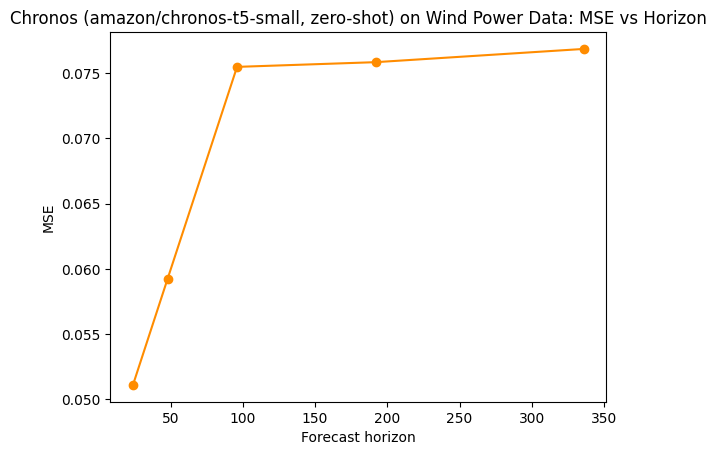

In [ ]:
import matplotlib.pyplot as plt

plt.plot(results_df.horizon, results_df.mse, marker="o", color="darkorange")
plt.xlabel("Forecast horizon")
plt.ylabel("MSE")
plt.title(f"Chronos ({MODEL_NAME}, zero-shot) on Wind Power Data: MSE vs Horizon")
plt.show()